# Week 9 Lab: Principal Component Analysis (PCA)
**CSE303 Machine Learning | Unit II: Dimensionality Reduction | Syllabus Exp 7 (covariance/correlation) and Exp 8 (PCA feature reduction)**

Pattern: **demo → practice → predict-then-run → deliberate error → reflection**.

| Part | Topic | Track |
|---|---|---|
| 1 | Covariance and correlation matrices | core |
| 2 | PCA by hand (the lecture's 5 steps) | core |
| 3 | PCA in sklearn, and what happens if you forget to scale | core |
| 4 | Mini Project A: PCA on digits (continues Week 7/8) | image |
| 5 | Mini Project B: PCA on the six sentences (continues Week 7/8) | NLP |
| 6 | Reflection and capstone link | |

**Rule carried from Week 5:** split first; fit the scaler and PCA on **train only**.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits, load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
np.set_printoptions(precision=4, suppress=True)

## Part 1: Covariance and Correlation (Exp 7)
Covariance: $Cov(X_i,X_j)=\frac{1}{n-1}\sum_k (X_{i,k}-\bar X_i)(X_{j,k}-\bar X_j)$. Correlation is covariance after standardizing, so it always lies in [-1, 1].

In [ ]:
iris = load_iris()
X = iris.data
print(iris.feature_names)
print('Covariance:\n', np.cov(X.T))
print('Correlation:\n', np.corrcoef(X.T))

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Covariance:
 [[ 0.6857 -0.0424  1.2743  0.5163]
 [-0.0424  0.19   -0.3297 -0.1216]
 [ 1.2743 -0.3297  3.1163  1.2956]
 [ 0.5163 -0.1216  1.2956  0.581 ]]
Correlation:
 [[ 1.     -0.1176  0.8718  0.8179]
 [-0.1176  1.     -0.4284 -0.3661]
 [ 0.8718 -0.4284  1.      0.9629]
 [ 0.8179 -0.3661  0.9629  1.    ]]


### Predict-then-run
Before running the next cell, write down: after `StandardScaler`, will `np.cov` of the scaled data equal `np.corrcoef` of the original data? ___

**Answer:** **No, `np.allclose` prints `False`.** `np.cov` divides by n−1 but `StandardScaler` standardizes with n, so every entry of the scaled covariance is larger by n/(n−1) = 150/149 ≈ **1.0067** (the printed ratio). The *direction* (correlation structure) is identical. Standardizing with ddof=1 would make them equal exactly.

In [ ]:
Xs = StandardScaler().fit_transform(X)
print(np.allclose(np.cov(Xs.T), np.corrcoef(X.T)))
print('ratio of the two matrices:', (np.cov(Xs.T) / np.corrcoef(X.T))[0, 0].round(4))

False
ratio of the two matrices: 1.0067


### Student Practice 1
1. Which two Iris features are most strongly correlated? Which pair is least?
2. Why is `np.cov(X.T)` used and not `np.cov(X)`?

In [ ]:
# Q1: strongest / weakest correlated pair (ignore the diagonal and duplicates)
R = np.corrcoef(X.T)
names = iris.feature_names
pairs = [(abs(R[i, j]), R[i, j], names[i], names[j]) for i in range(4) for j in range(i + 1, 4)]
pairs.sort(reverse=True)
for a, r, f1, f2 in pairs:
    print(f'{r:+.4f}  {f1}  vs  {f2}')
print('\nMost correlated :', pairs[0][2], '&', pairs[0][3], round(pairs[0][1], 4))
print('Least correlated:', pairs[-1][2], '&', pairs[-1][3], round(pairs[-1][1], 4))

# Q2: shape check
print('\nnp.cov(X.T).shape =', np.cov(X.T).shape, '(4 x 4, one row per feature)')
print('np.cov(X).shape   =', np.cov(X).shape, '(150 x 150, one row per SAMPLE, wrong)')

+0.9629  petal length (cm)  vs  petal width (cm)
+0.8718  sepal length (cm)  vs  petal length (cm)
+0.8179  sepal length (cm)  vs  petal width (cm)
-0.4284  sepal width (cm)  vs  petal length (cm)
-0.3661  sepal width (cm)  vs  petal width (cm)
-0.1176  sepal length (cm)  vs  sepal width (cm)

Most correlated : petal length (cm) & petal width (cm) 0.9629
Least correlated: sepal length (cm) & sepal width (cm) -0.1176

np.cov(X.T).shape = (4, 4) (4 x 4, one row per feature)
np.cov(X).shape   = (150, 150) (150 x 150, one row per SAMPLE, wrong)


**Answers (Student Practice 1)**
1. **Most correlated:** petal length and petal width (**r = 0.9629**). **Least correlated:** sepal length and sepal width (**r = −0.1176**), which is the pair closest to zero. (Petal length and sepal length, 0.872, is also strongly correlated.)
2. Features are the **columns** of `X` (150 samples × 4 features), but `np.cov` treats **rows as variables**. `np.cov(X)` would give a 150×150 matrix of covariances between *samples*; `np.cov(X.T)` gives the 4×4 covariance between *features*, which is what PCA needs.

## Part 2: PCA by Hand (the lecture's 5 steps)
Data: 4 students, two features (hours studied $X_1$, marks-related score $X_2$):

| | X1 | X2 |
|---|---|---|
| a | 4 | 11 |
| b | 8 | 4 |
| c | 13 | 5 |
| d | 7 | 14 |

Steps: (1) standardize, (2) covariance matrix, (3) eigenvalues from $\det(C-\lambda I)=0$ and eigenvectors from $Cv=\lambda v$, (4) choose PCs, (5) project $Z=XV$.

In [ ]:
D = np.array([[4, 11], [8, 4], [13, 5], [7, 14]], float)
mean, std = D.mean(0), D.std(0, ddof=1)
Zs = (D - mean) / std
print('mean', mean, 'std', std)
print('standardized:\n', Zs)
C = Zs.T @ Zs / (len(D) - 1)
print('covariance of standardized data:\n', C)

mean [8.  8.5] std [3.7417 4.7958]
standardized:
 [[-1.069   0.5213]
 [ 0.     -0.9383]
 [ 1.3363 -0.7298]
 [-0.2673  1.1468]]
covariance of standardized data:
 [[ 1.    -0.613]
 [-0.613  1.   ]]


### Student Practice 2 (do on paper first, as in an exam)
For $C=\begin{pmatrix}1&r\\r&1\end{pmatrix}$:
1. Show the characteristic equation is $(1-\lambda)^2-r^2=0$, so $\lambda=1\pm r$.
2. Using the value of $r$ printed above, write both eigenvalues. (Hint: r is negative.)
3. Explained variance of PC1 = $\lambda_1/(\lambda_1+\lambda_2)$ = ___ %
4. Eigenvector for the larger eigenvalue (roughly ±0.71, ∓0.71 pattern): ___

In [ ]:
# Hand answers (r is the off-diagonal of C)
r = C[0, 1]
lam_hand = np.array([1 + r, 1 - r])           # lambda = 1 +/- r
print('r =', round(r, 4))
print('Hand eigenvalues      : lambda1 =', round(1 - r, 4), ', lambda2 =', round(1 + r, 4))
print('PC1 explained variance:', round((1 - r) / 2 * 100, 2), '%')

# Verify with numpy (eigh returns ascending order, so reverse it)
vals, vecs = np.linalg.eigh(C)
vals, vecs = vals[::-1], vecs[:, ::-1]
print('\neigh eigenvalues :', vals)
print('eigh eigenvectors (columns):\n', vecs)
print('explained variance ratio  :', vals / vals.sum())
print('check C v = lambda v      :', np.allclose(C @ vecs[:, 0], vals[0] * vecs[:, 0]))

# Step 5: project Z = Zs V
Z = Zs @ vecs
print('\nProjected data Z (PC1, PC2):\n', Z)
print('PC1 only, one number per student:', Z[:, 0])

r = -0.613
Hand eigenvalues      : lambda1 = 1.613 , lambda2 = 0.387
PC1 explained variance: 80.65 %

eigh eigenvalues : [1.613 0.387]
eigh eigenvectors (columns):
 [[-0.7071 -0.7071]
 [ 0.7071 -0.7071]]
explained variance ratio  : [0.8065 0.1935]
check C v = lambda v      : True

Projected data Z (PC1, PC2):
 [[ 1.1245  0.3873]
 [-0.6635  0.6635]
 [-1.461  -0.4289]
 [ 0.9999 -0.6219]]
PC1 only, one number per student: [ 1.1245 -0.6635 -1.461   0.9999]


**Hand solution (Student Practice 2, write this on paper)**

Data: mean X1 = 8, mean X2 = 8.5; std X1 = 3.742, std X2 = 4.796 (sample std, n−1 = 3). Standardized values:

| | z1 | z2 |
|---|---|---|
| a | −1.069 | 0.521 |
| b | 0.000 | −0.938 |
| c | 1.336 | −0.730 |
| d | −0.267 | 1.147 |

Covariance of standardized data: C = [[1, r], [r, 1]] with **r = −0.613**.

1. det(C − λI) = (1 − λ)(1 − λ) − r·r = **(1 − λ)² − r² = 0**, so 1 − λ = ±r, giving **λ = 1 ± r**.
2. With r = −0.613: **λ₁ = 1 + 0.613 = 1.613** and **λ₂ = 1 − 0.613 = 0.387**. (Sum = 2 = trace of C.)
3. Explained variance of PC1 = 1.613 / (1.613 + 0.387) = 1.613 / 2 = **80.65 %**.
4. For λ₁ = 1.613: (C − λI)v = 0 gives −0.613 v₁ − 0.613 v₂ = 0 hence v₂ = −v₁, normalised: **v₁ = (1/√2)(1, −1) ≈ (0.707, −0.707)** (the sign ± is arbitrary; numpy prints (−0.707, 0.707)). For λ₂: **v₂ = (0.707, 0.707)**.

Projection onto PC1: Z = Zs · v₁ gives one score per student (magnitudes ≈ 1.12, 0.66, 1.46, 1.00; signs depend on the sign chosen for v₁).

### Predict-then-run
If you project onto PC1 only, how many numbers describe each student? ___. Run `Z[:, 0]` after finishing the verification to see them.

**Answer:** **1 number per student** (instead of 2). `Z[:, 0]` gives one PC1 score for each of the 4 students.

## Part 3: PCA in sklearn, and the Scaling Error
Use the **Wine** dataset (13 chemical measurements, very different units).

In [ ]:
wine = load_wine()
Xw = wine.data
print('feature std devs:', Xw.std(0).round(2))
raw = PCA().fit(Xw)
print('NO scaling, PC1 explains:', round(raw.explained_variance_ratio_[0], 4))

feature std devs: [  0.81   1.11   0.27   3.33  14.24   0.62   1.     0.12   0.57   2.31
   0.23   0.71 314.02]
NO scaling, PC1 explains: 0.9981


### Predict-then-run
PC1 of the unscaled data explains how much? Guess before looking: <50% / 50-80% / >95%. Then scale and compare below. **Deliberate error:** the unscaled result is misleading. Explain why in one line.

**Answer:** **>95%.** Unscaled PC1 explains **99.81%**.

**Deliberate error, why it is misleading (one line):** PCA maximises variance, and variance depends on the units. `proline` has a std of about 314 while most other features are below 15, so PC1 is just the `proline` column and the other 12 features are ignored. It reflects units, not information.

WITH scaling, first 3 ratios: [0.362  0.1921 0.1112]


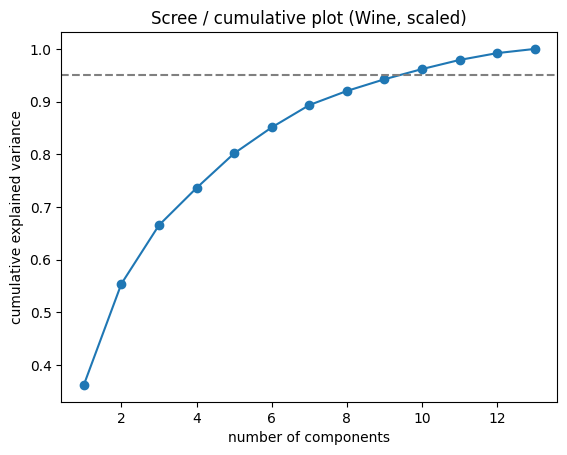

In [ ]:
scaled = PCA().fit(StandardScaler().fit_transform(Xw))
print('WITH scaling, first 3 ratios:', scaled.explained_variance_ratio_[:3].round(4))
cum = np.cumsum(scaled.explained_variance_ratio_)
plt.plot(range(1, 14), cum, 'o-'); plt.axhline(0.95, ls='--', c='gray')
plt.xlabel('number of components'); plt.ylabel('cumulative explained variance'); plt.title('Scree / cumulative plot (Wine, scaled)')
plt.show()

### Student Practice 3
1. How many components are needed to reach 95% variance on scaled Wine?
2. In the lecture's PCA steps, which step did the unscaled run skip?

In [ ]:
wine_scaled = StandardScaler().fit_transform(Xw)
cum_w = np.cumsum(PCA().fit(wine_scaled).explained_variance_ratio_)
print('Cumulative variance:', cum_w.round(4))
print('Components for 95% (scaled Wine):', int(np.argmax(cum_w >= 0.95)) + 1, 'of 13')
print('Components for 90% (scaled Wine):', int(np.argmax(cum_w >= 0.90)) + 1, 'of 13')

Cumulative variance: [0.362  0.5541 0.6653 0.736  0.8016 0.851  0.8934 0.9202 0.9424 0.9617
 0.9791 0.992  1.    ]
Components for 95% (scaled Wine): 10 of 13
Components for 90% (scaled Wine): 8 of 13


**Answers (Student Practice 3)**
1. **10 components** are needed to reach 95% on scaled Wine (10 of 13). Scaled PC1, PC2, PC3 explain 36.2%, 19.2%, 11.1%.
2. The unscaled run skipped **Step 1: standardize the data** (subtract the mean and divide by the std). Without it, the covariance matrix is dominated by the large-unit feature `proline`, and PC1 explains 99.8%.

# Mini Project A: PCA on Digits (Image Track — continuing from Weeks 7 and 8)
Same split as before (`test_size=0.3, random_state=1, stratify`). Baselines you already have: **KNN (scaled, K=3) = 0.9796** and **Tree (entropy, full depth, unscaled) = 0.8815**. Question: how many of the 64 pixels-worth of information do we really need?

In [ ]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)
sc = StandardScaler().fit(Xd_train)                 # fit on TRAIN only
Xtr, Xte = sc.transform(Xd_train), sc.transform(Xd_test)
pca = PCA().fit(Xtr)                                # fit on TRAIN only
cum = np.cumsum(pca.explained_variance_ratio_)
for t in [0.80, 0.90, 0.95, 0.99]:
    print(f'{int(t*100)}% variance needs', int(np.argmax(cum >= t)) + 1, 'of 64 components')

80% variance needs 21 of 64 components
90% variance needs 31 of 64 components
95% variance needs 40 of 64 components
99% variance needs 54 of 64 components


### Predict-then-run
How many components for 90% of the variance? Guess: ~5 / ~15 / ~30 / ~55. And what will KNN accuracy look like with only 10 components?

**Answer:** about **~30** (it turns out to be **31** of 64). With only 10 components KNN is still strong (about **94%**), well below the 97.96% baseline but far above chance, as the table in Student Practice 4 shows.

### Student Practice 4
1. For k in [2, 5, 10, 20, 30, 40, 64] fit PCA(k) on `Xtr`, transform train and test, and report KNN (K=3) and Tree (entropy, random_state=1) test accuracy.
2. Which k values give KNN within 0.5 percentage points of the full-pixel baseline 0.9796?
3. Does the tree improve, stay the same, or get worse with PCA features compared with its raw-pixel 0.8815? Why might that be? (Think: what do tree splits do to axes?)

Baselines: KNN (64 scaled pixels) = 0.9796, Tree (raw pixels) = 0.8815

 k |  KNN   |  Tree  | KNN within 0.5pp of baseline?


 2 | 0.5648 | 0.4944 | no


 5 | 0.8759 | 0.7759 | no
10 | 0.9426 | 0.8241 | no
20 | 0.9722 | 0.8222 | no


30 | 0.9778 | 0.8185 | YES


40 | 0.9759 | 0.8222 | YES


64 | 0.9796 | 0.8167 | YES


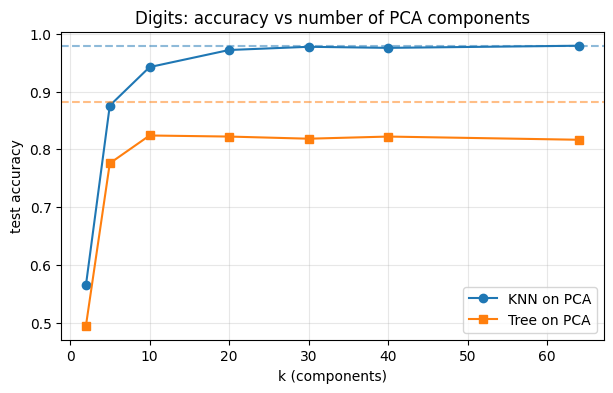

In [ ]:
base_knn = KNeighborsClassifier(3).fit(Xtr, yd_train).score(Xte, yd_test)
base_tree = DecisionTreeClassifier(criterion='entropy', random_state=1).fit(Xd_train, yd_train).score(Xd_test, yd_test)
print(f'Baselines: KNN (64 scaled pixels) = {base_knn:.4f}, Tree (raw pixels) = {base_tree:.4f}\n')

rows = []
print(' k |  KNN   |  Tree  | KNN within 0.5pp of baseline?')
for k in [2, 5, 10, 20, 30, 40, 64]:
    pk = PCA(k).fit(Xtr)
    a, b = pk.transform(Xtr), pk.transform(Xte)
    knn_acc = KNeighborsClassifier(3).fit(a, yd_train).score(b, yd_test)
    tree_acc = DecisionTreeClassifier(criterion='entropy', random_state=1).fit(a, yd_train).score(b, yd_test)
    ok = (base_knn - knn_acc) <= 0.005
    rows.append((k, knn_acc, tree_acc, ok))
    print(f'{k:2d} | {knn_acc:.4f} | {tree_acc:.4f} | {"YES" if ok else "no"}')

plt.figure(figsize=(7, 4))
plt.plot([r[0] for r in rows], [r[1] for r in rows], 'o-', label='KNN on PCA')
plt.plot([r[0] for r in rows], [r[2] for r in rows], 's-', label='Tree on PCA')
plt.axhline(base_knn, ls='--', c='C0', alpha=.5); plt.axhline(base_tree, ls='--', c='C1', alpha=.5)
plt.xlabel('k (components)'); plt.ylabel('test accuracy'); plt.legend(); plt.grid(alpha=.3)
plt.title('Digits: accuracy vs number of PCA components'); plt.show()

**Answers (Student Practice 4)**

| k | KNN | Tree |
|---|---|---|
| 2 | 0.5648 | 0.4944 |
| 5 | 0.8759 | 0.7759 |
| 10 | 0.9426 | 0.8241 |
| 20 | 0.9722 | 0.8222 |
| 30 | 0.9778 | 0.8185 |
| 40 | 0.9759 | 0.8222 |
| 64 | 0.9796 | 0.8167 |

1. Table above (KNN K=3, Tree entropy random_state=1). Variance needed: 80% → 21, 90% → 31, 95% → 40, 99% → 54 components.
2. **k = 30, 40 and 64** are within 0.5 percentage points of 0.9796 (need ≥ 0.9746). k = 20 (0.9722) just misses.
3. The tree gets **worse**: about 0.82 with PCA features versus **0.8815** on raw pixels. A tree splits on **one feature at a time** (axis-aligned thresholds). Raw pixels are meaningful single features, but each PC is a **mix of all 64 pixels**, so a single-PC threshold is a weaker question. PCA also ranks directions by variance, not by usefulness for class separation, so the tree gains nothing from the rotation.

### Look at the components
Each principal component is a 64-number vector, i.e. an 8×8 image.

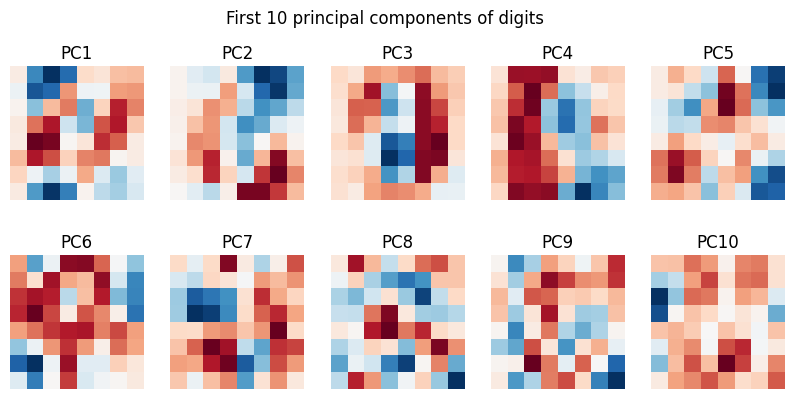

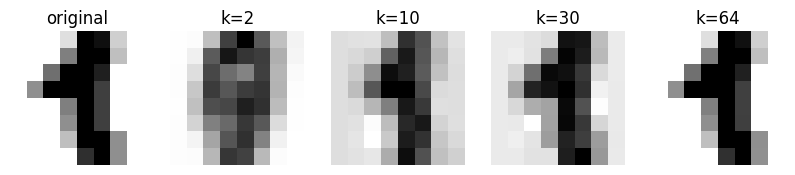

In [ ]:
fig, ax = plt.subplots(2, 5, figsize=(10, 4.5))
for i, a in enumerate(ax.ravel()):
    a.imshow(pca.components_[i].reshape(8, 8), cmap='RdBu'); a.set_title(f'PC{i+1}'); a.axis('off')
plt.suptitle('First 10 principal components of digits'); plt.show()

# reconstruction of one digit from k components
k_list = [2, 10, 30, 64]
fig, ax = plt.subplots(1, 5, figsize=(10, 2.5))
ax[0].imshow(Xd_test[0].reshape(8, 8), cmap='gray_r'); ax[0].set_title('original'); ax[0].axis('off')
for a, k in zip(ax[1:], k_list):
    pk = PCA(k).fit(Xtr)
    rec = sc.inverse_transform(pk.inverse_transform(pk.transform(Xte[:1])))
    a.imshow(rec.reshape(8, 8), cmap='gray_r'); a.set_title(f'k={k}'); a.axis('off')
plt.show()

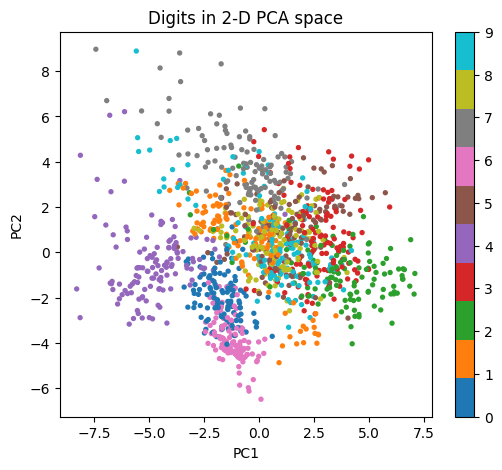

In [ ]:
# 2-D view: can two components separate the ten digits?
Z2 = PCA(2).fit(Xtr).transform(Xtr)
plt.figure(figsize=(6, 5)); sc_ = plt.scatter(Z2[:, 0], Z2[:, 1], c=yd_train, cmap='tab10', s=8)
plt.colorbar(sc_); plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Digits in 2-D PCA space'); plt.show()

### Deliberate error: fitting PCA on all the data
Run the cell below, then answer: why is this wrong even if the accuracy looks fine?

In [ ]:
scaler_all = StandardScaler().fit(digits.data)           # WRONG: sees test rows
p_all = PCA(30).fit(scaler_all.transform(digits.data))   # WRONG
a = p_all.transform(scaler_all.transform(Xd_train)); b = p_all.transform(scaler_all.transform(Xd_test))
print('leaky KNN k=30:', KNeighborsClassifier(3).fit(a, yd_train).score(b, yd_test))

leaky KNN k=30: 0.9777777777777777


**Answer (deliberate error):** The leaky KNN scores **0.9778** (the same as the correct k=30 result), so the accuracy looks fine. It is still wrong because `StandardScaler` and `PCA` were fitted on **all** the data, so the test rows influenced the means, scales and principal directions. The test set is no longer unseen, so the score is not an honest estimate of performance on new data. The leak is small here, but the rule is fixed: split first, then fit scaler and PCA on **train only**.

# Mini Project B: PCA on the Six Sentences (NLP Track — continuing from Weeks 7 and 8)
Same sentences and bag-of-words vectors. Question: can a 2-D picture show the three topics?

In [ ]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']
vocab = sorted(set(w for s in sentences for w in s.lower().split()))
X_text = np.array([[s.lower().split().count(w) for w in vocab] for s in sentences])
print('matrix shape (docs x vocab):', X_text.shape)

matrix shape (docs x vocab): (6, 29)


### Predict-then-run
The matrix has 6 rows and 29 columns. (a) What is the maximum number of non-zero principal components? (b) Will 2 components capture >90% of variance?

**Answer:** (a) **5**. After centering, 6 documents span at most n−1 = 5 dimensions, so at most 5 PCs are non-zero, even though there are 29 columns. (b) **No.** 2 components capture only **47.3%** of the variance (26.4% + 20.9%).

### Student Practice 5
1. Fit `PCA(2)` on `X_text` (no scaling, counts are already comparable). Print `explained_variance_ratio_` and its sum.
2. Scatter-plot the 6 points, colour by label, annotate with the sentence number.
3. Do same-topic sentences land near each other? Which pair does PCA place closest?
4. Print the 5 words with the largest absolute weight on PC1 and PC2.

explained_variance_ratio_: [0.2642 0.2088]  sum = 0.4731
Max non-zero PCs: 5 (= min(n-1, p) = min(5, 29))
Cumulative with all comps: [0.2642 0.4731 0.6679 0.8401 1.     1.    ]


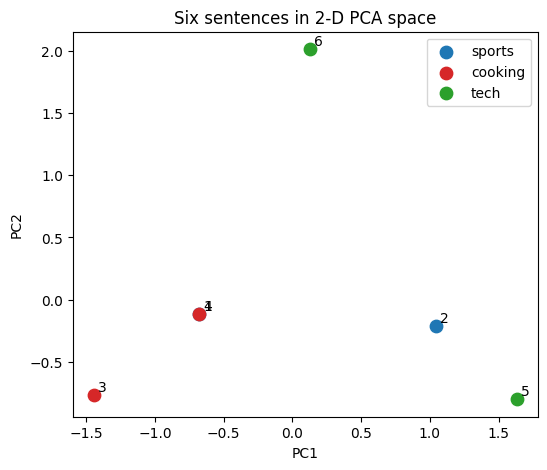

Closest pairs (distance, sentence a, sentence b):
  0.0000  S1 (sports) - S4 (cooking)
  0.8312  S2 (sports) - S5 (tech)
  1.0030  S1 (sports) - S3 (cooking)
  1.0030  S3 (cooking) - S4 (cooking)
PC1 top words: [('a', 0.395), ('and', -0.313), ('the', -0.313), ('faster', 0.24), ('phone', 0.24)]
PC2 top words: [('all', 0.376), ('battery', 0.376), ('lasts', 0.376), ('day', 0.376), ('laptop', 0.376)]


In [ ]:
# 1. PCA(2), no scaling
pt = PCA(2).fit(X_text)
Zt = pt.transform(X_text)
print('explained_variance_ratio_:', pt.explained_variance_ratio_, ' sum =', round(pt.explained_variance_ratio_.sum(), 4))
print('Max non-zero PCs:', np.linalg.matrix_rank(X_text - X_text.mean(0)), '(= min(n-1, p) = min(5, 29))')
print('Cumulative with all comps:', np.cumsum(PCA().fit(X_text).explained_variance_ratio_).round(4))

# 2. Scatter plot
colors = {'sports': 'tab:blue', 'cooking': 'tab:red', 'tech': 'tab:green'}
plt.figure(figsize=(6, 5))
for i, (z, lab) in enumerate(zip(Zt, labels)):
    plt.scatter(z[0], z[1], c=colors[lab], s=80, label=lab if lab not in plt.gca().get_legend_handles_labels()[1] else None)
    plt.annotate(str(i + 1), (z[0] + .03, z[1] + .03))
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.legend(); plt.title('Six sentences in 2-D PCA space'); plt.show()

# 3. Closest pairs
from itertools import combinations
d = sorted(((np.linalg.norm(Zt[i] - Zt[j]), i + 1, j + 1) for i, j in combinations(range(6), 2)))
print('Closest pairs (distance, sentence a, sentence b):')
for dist, i, j in d[:4]:
    print(f'  {dist:.4f}  S{i} ({labels[i-1]}) - S{j} ({labels[j-1]})')

# 4. Top words per PC
for c in range(2):
    idx = np.argsort(-np.abs(pt.components_[c]))[:5]
    print(f'PC{c+1} top words:', [(vocab[i], round(float(pt.components_[c][i]), 3)) for i in idx])

**Answers (Student Practice 5)**
1. `explained_variance_ratio_` = [0.2642, 0.2088], **sum = 0.473**.
2. See the scatter plot above (S1 and S4 land on exactly the same point; S6 is far above on PC2).
3. **No, same-topic sentences do not land together.** The closest pair is **S1 (sports) and S4 (cooking)**, which sit at the identical point (distance ≈ 0). The sports pair (S1, S2) is about 1.7 apart. Only 47% of the variance is shown in 2-D, so the picture cannot separate the 3 topics.
4. **PC1:** `a` (+0.395), `and` and `the` (−0.313 each), `faster` and `phone` (+0.24 each), i.e. it is driven mostly by common function words. **PC2:** all, battery, lasts, day, laptop (each 0.376), i.e. it is essentially the single sentence S6 ("the laptop battery lasts all day"). Bag-of-words counts of common words carry most of the variance, not topic.

## Part 6: Reflection (write 2–3 lines each)
1. In your own words: what does PCA keep and what does it throw away?
2. Why must we standardize before PCA? Give the Wine evidence.
3. Digits: pick the k you would deploy and justify (accuracy vs. size).
4. PCA helped KNN but not the tree. What does this say about when to use PCA?
5. PCA is **unsupervised**; it never looked at the labels. What could go wrong? (This sets up LDA, the next topic in Unit II.)
6. **Capstone link (Milestone, Week 9):** will PCA belong in your pipeline? If yes, show the cumulative-variance plot and the accuracy-vs-k table in your repo's `notebooks/` folder; if no, justify.

**Reflection answers**

1. PCA **keeps** the directions (linear combinations of features) along which the data varies the most, and **throws away** the low-variance directions, treated as noise or redundancy. Components are orthogonal and ordered by variance, so the first few carry most of the information.

2. PCA maximises variance, and variance depends on units. Wine evidence: unscaled PC1 explains **99.81%** because `proline` (std ≈ 314) swamps the others; after `StandardScaler` PC1 explains only **36.2%** and 10 components are needed for 95%. Standardizing gives every feature equal footing.

3. I would deploy **k = 30**: KNN accuracy is **0.9778**, only about 0.2 pp below the 64-pixel baseline of 0.9796 (inside the 0.5 pp rule), with fewer than half of the dimensions. If size or speed matters more, k = 20 gives 0.9722 with 31% of the features. Below k = 10 the accuracy drops sharply (k = 2: 0.565).

4. KNN works on distances, so removing noisy and redundant dimensions keeps the distances meaningful and the model fast; at k ≥ 30 it matches the baseline. A tree splits on single features, and PCA mixes all pixels into each component (0.8815 → about 0.82). So use PCA for **distance-based or linear models and for visualization / compression**; do not expect it to help trees.

5. PCA is unsupervised, so it keeps the directions of **largest variance**, not the ones that **separate the classes**. A direction that separates classes may have small variance and get discarded, and a high-variance direction may be irrelevant to the labels. We saw it in the plots: the 2-D digit view overlaps heavily, and in the sentence data sports and cooking sentences S1 and S4 coincide. LDA uses the labels to find directions that separate the classes.

6. No, PCA will not belong in this pipeline because our engineered behavioral features (Recency, Frequency, Monetary) naturally form a low-dimensional space, whereas the lab guidelines specify PCA "if high-dimensional". Furthermore, because this model informs direct-to-consumer marketing decisions, applying PCA would project our interpretable RFM metrics into abstract principal components, destroying the business's ability to explain exactly why a specific customer was flagged as a churn risk. Finally, our predictive classification relies on tree-based ensemble models, which natively handle feature collinearity and do not benefit from PCA's distance-based transformations.

*Submit this notebook to GitHub under `labs/week9_pca/`.*